# Maintenance prédictive MECHA — Comparaison de modèles

**MSPR TPRE822 — IA MECHA**

Ce notebook entraîne et compare plusieurs modèles pour les deux tâches ML du projet :
1. **Classification** de l'état machine (`normal` / `a_surveiller` / `a_risque`)
2. **Régression** du RUL (Remaining Useful Life)

L'objectif est de **justifier par les mesures** le choix des modèles finaux.

**Modèles comparés** (du plus simple au plus complexe) :

| Famille | Classification | Régression |
|---|---|---|
| Baseline linéaire | Logistic Regression | Linear Regression |
| Arbre unique | Decision Tree | Decision Tree Regressor |
| Ensemble bagging | Random Forest | Random Forest Regressor |
| Ensemble boosting (sklearn) | Gradient Boosting | Gradient Boosting Regressor |
| Ensemble boosting (XGBoost) | XGBoost Classifier | XGBoost Regressor |
| Instance-based | K-Nearest Neighbors | — |


## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import time

from sklearn.model_selection import train_test_split, GroupKFold
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestClassifier, RandomForestRegressor,
    GradientBoostingClassifier, GradientBoostingRegressor,
)
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier, XGBRegressor

from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score, recall_score,
    mean_absolute_error, mean_squared_error, r2_score,
)

pd.set_option("display.max_columns", 30)


## 2. Chargement des données

Utilise CMAPSS réel si présent, sinon génère un jeu synthétique de repli.

In [2]:
RAW_PATH = Path("raw/train_FD001.txt")
COLS = (["machine_id", "cycle_number", "op_setting_1", "op_setting_2", "op_setting_3"]
        + [f"sensor_{i}" for i in range(1, 22)])

def generate_synthetic_cmapss(n_machines=50, seed=42):
    rng = np.random.default_rng(seed)
    rows = []
    for m in range(1, n_machines + 1):
        life = rng.integers(120, 260)
        degradation = np.linspace(0, 1, life) ** 1.5
        for c in range(1, life + 1):
            d = degradation[c - 1]
            row = {"machine_id": m, "cycle_number": c,
                   "op_setting_1": rng.normal(0, 0.02),
                   "op_setting_2": rng.normal(0, 0.02),
                   "op_setting_3": 100.0}
            for i in range(1, 22):
                row[f"sensor_{i}"] = 400 + i*10 + d*rng.uniform(5, 30) + rng.normal(0, 1.5)
            rows.append(row)
    return pd.DataFrame(rows)

if RAW_PATH.exists():
    df_raw = pd.read_csv(RAW_PATH, sep=r"\s+", header=None, names=COLS)
    print("Source : CMAPSS FD001 (réel)")
else:
    df_raw = generate_synthetic_cmapss()
    print("Source : synthétique (repli)")

print(f"Shape : {df_raw.shape}")


Source : synthétique (repli)
Shape : (9200, 26)


## 3. Traitement des valeurs aberrantes

**Ce que fait un capteur industriel qui déraille** : un pic de tension, une
coupure réseau, un défaut de calibration produisent des valeurs physiquement
impossibles (température négative en Kelvin, vibration négative...). Il faut
les corriger.

**Le piège à éviter** : une valeur *extrême mais réelle* (vibration qui monte
en fin de vie machine) est exactement le signal qu'on veut prédire — la
supprimer reviendrait à supprimer les vraies pannes du jeu d'entraînement.

**Méthode retenue** :
1. Bornes physiques absolues (valeurs impossibles) → suppression de la ligne
2. Détection statistique par IQR **calculée par machine** (pas globalement) —
   une valeur extrême est normale en fin de vie, suspecte en début de vie
3. **Winsorisation** (écrêtage vers les bornes) plutôt que suppression — on
   garde la trajectoire complète de la machine intacte pour le calcul du RUL

In [3]:
from src.cleaning import winsorize_by_machine, detect_sensor_alerts

SENSOR_RENAME = {
    "sensor_2": "temperature_moteur", "sensor_3": "temperature_lubrifiant",
    "sensor_4": "temperature_carter", "sensor_7": "pression_hydraulique",
    "sensor_9": "vitesse_broche", "sensor_11": "vibration_axe_x",
    "sensor_12": "vibration_axe_y", "sensor_14": "debit_refroidissement",
    "sensor_15": "humidite_ambiante", "sensor_21": "indice_usure_outil",
}
FEATURES = list(SENSOR_RENAME.values())
FEATURES_RAW = [c for c in df_raw.columns if c.startswith("sensor_")]

# --- 1. Bornes physiques absolues (valeurs impossibles, indépendantes du contexte) ---
before = len(df_raw)
df_bounded = df_raw[(df_raw[FEATURES_RAW] > 0).all(axis=1)].copy()  # aucun capteur ne doit être négatif
print(f"Lignes supprimées (valeurs physiquement impossibles) : {before - len(df_bounded)}")

# --- 2. Détection IQR par machine (préserve le signal de dégradation) ---
# Logique partagée avec le pipeline d'inférence et testée unitairement (voir src/cleaning.py, tests/test_outliers.py)
df_clean, outlier_events, n_capped = winsorize_by_machine(df_bounded, FEATURES_RAW, k=3.0)
print(f"Valeurs écrêtées (winsorisation, {n_capped / (len(df_clean)*len(FEATURES_RAW)):.2%} du total) : {n_capped}")


Lignes supprimées (valeurs physiquement impossibles) : 0


Valeurs écrêtées (winsorisation, 0.00% du total) : 6


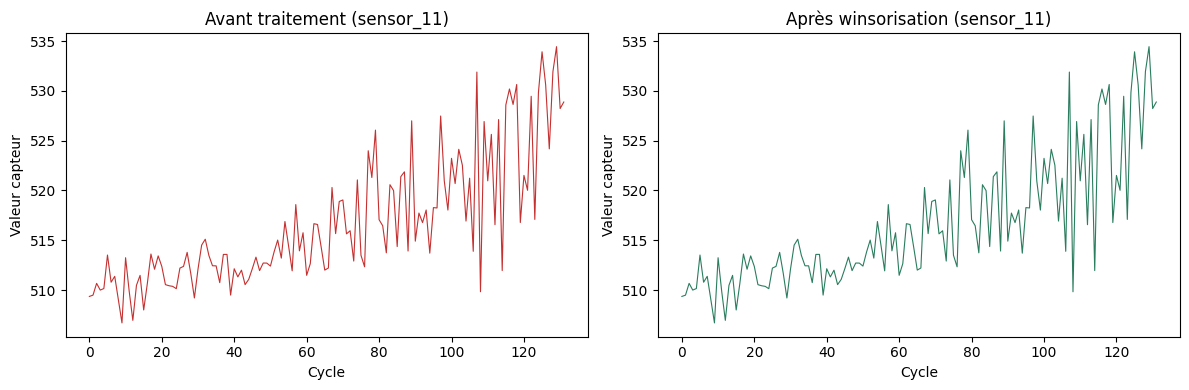

In [4]:
# Visualisation avant / après sur un capteur exemple
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sample_machine = df_raw["machine_id"].iloc[0]

before_data = df_raw[df_raw["machine_id"] == sample_machine]["sensor_11"]
after_data  = df_clean[df_clean["machine_id"] == sample_machine]["sensor_11"]

axes[0].plot(before_data.values, color="#c53030", linewidth=0.8)
axes[0].set_title("Avant traitement (sensor_11)")
axes[0].set_xlabel("Cycle"); axes[0].set_ylabel("Valeur capteur")

axes[1].plot(after_data.values, color="#2a7d5f", linewidth=0.8)
axes[1].set_title("Après winsorisation (sensor_11)")
axes[1].set_xlabel("Cycle"); axes[1].set_ylabel("Valeur capteur")

plt.tight_layout()
plt.show()


## 4. Alerte capteur défaillant

**Distinction importante** : une machine `a_risque` signale un problème
**mécanique** (la machine se dégrade réellement). Une alerte capteur signale
un problème **instrumental** (le capteur lui-même déraille — câble, calibration,
interférence électrique). Ce sont deux causes racines différentes, traitées
par deux équipes différentes (maintenance mécanique vs instrumentation).

**Règle retenue** : si un même capteur, sur une même machine, produit
**3 valeurs aberrantes ou plus**, on considère que c'est le capteur qui est
suspect — pas la machine.

In [5]:
SEUIL_ALERTE_CAPTEUR = 3

sensor_alerts = detect_sensor_alerts(outlier_events, threshold=SEUIL_ALERTE_CAPTEUR)
if not sensor_alerts.empty:
    sensor_alerts["sensor"] = sensor_alerts["sensor"].map(SENSOR_RENAME).fillna(sensor_alerts["sensor"])
    sensor_alerts = sensor_alerts.sort_values("nb_aberrations", ascending=False)

print(f"Capteurs suspects (>= {SEUIL_ALERTE_CAPTEUR} valeurs aberrantes) : {len(sensor_alerts)}")
sensor_alerts


Capteurs suspects (>= 3 valeurs aberrantes) : 1


,machine_id,sensor,nb_aberrations,premier_cycle,dernier_cycle
1,28,sensor_1,3,128,137


In [6]:
Path("outputs").mkdir(exist_ok=True)
sensor_alerts.to_csv("outputs/alertes_capteurs.csv", index=False)
print("Sauvegardé : outputs/alertes_capteurs.csv")


Sauvegardé : outputs/alertes_capteurs.csv


## 5. Préparation — RUL, renommage, label de risque

In [7]:
df = df_clean.drop_duplicates().copy()
df["RUL"] = df.groupby("machine_id")["cycle_number"].transform("max") - df["cycle_number"]
df = df.rename(columns=SENSOR_RENAME)
df = df[["machine_id", "cycle_number"] + FEATURES + ["RUL"]]
df["risk_level"] = pd.cut(df["RUL"], bins=[-1, 15, 50, np.inf],
                          labels=["a_risque", "a_surveiller", "normal"])

print(df["risk_level"].value_counts())


risk_level
normal          6650
a_surveiller    1750
a_risque         800
Name: count, dtype: int64


## 6. Split train / test **par machine**

Un split ligne par ligne mélangerait début et fin de vie d'une même machine
entre train et test → fuite de données.

In [8]:
machines = df["machine_id"].unique()
train_m, test_m = train_test_split(machines, test_size=0.2, random_state=42)

df_train = df[df["machine_id"].isin(train_m)]
df_test  = df[df["machine_id"].isin(test_m)]

X_train, X_test = df_train[FEATURES], df_test[FEATURES]
y_train_clf, y_test_clf = df_train["risk_level"], df_test["risk_level"]
y_train_reg, y_test_reg = df_train["RUL"], df_test["RUL"]

print(f"Train : {len(df_train)} lignes ({len(train_m)} machines)")
print(f"Test  : {len(df_test)} lignes ({len(test_m)} machines)")


Train : 7335 lignes (40 machines)
Test  : 1865 lignes (10 machines)


## 7. Comparaison des modèles de **classification**

Métriques suivies :
- **Accuracy** : justesse globale
- **F1 macro** : moyenne du F1 par classe (traite les classes à égalité)
- **Recall `a_risque`** : **métrique métier prioritaire** — minimiser les vraies pannes ratées

Les modèles linéaires et KNN sont mis dans un `Pipeline` avec `StandardScaler`
(ils sont sensibles aux échelles). Les arbres ne le sont pas.

In [9]:
def eval_classifier(name, model, X_tr, y_tr, X_te, y_te):
    t0 = time.time()
    model.fit(X_tr, y_tr)
    fit_time = time.time() - t0
    y_pred = model.predict(X_te)
    return {
        "model": name,
        "accuracy": round(accuracy_score(y_te, y_pred), 3),
        "f1_macro": round(f1_score(y_te, y_pred, average="macro"), 3),
        "recall_a_risque": round(recall_score(y_te, y_pred, labels=["a_risque"], average="macro"), 3),
        "fit_time_s": round(fit_time, 2),
    }

classifiers = {
    "Logistic Regression": Pipeline([("sc", StandardScaler()),
                                     ("m", LogisticRegression(max_iter=1000, class_weight="balanced"))]),
    "Decision Tree":       DecisionTreeClassifier(max_depth=10, class_weight="balanced", random_state=42),
    "Random Forest":       RandomForestClassifier(n_estimators=200, max_depth=10,
                                                  class_weight="balanced", random_state=42, n_jobs=-1),
    "Gradient Boosting":   GradientBoostingClassifier(n_estimators=200, max_depth=5, random_state=42),
    "KNN (k=5)":           Pipeline([("sc", StandardScaler()),
                                     ("m", KNeighborsClassifier(n_neighbors=5))]),
    "XGBoost":             XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                                         random_state=42, n_jobs=-1, eval_metric="mlogloss"),
}

# XGBoost requiert des labels numériques (pas de strings). Encodage local.
from sklearn.preprocessing import LabelEncoder
_LE = LabelEncoder().fit(y_train_clf)


clf_results = []
for n, m in classifiers.items():
    if n == "XGBoost":
        # Entraînement sur labels encodés, décodage avant scoring
        t0 = time.time()
        m.fit(X_train, _LE.transform(y_train_clf))
        fit_time = time.time() - t0
        y_pred = _LE.inverse_transform(m.predict(X_test))
        clf_results.append({
            "model": n,
            "accuracy": round(accuracy_score(y_test_clf, y_pred), 3),
            "f1_macro": round(f1_score(y_test_clf, y_pred, average="macro"), 3),
            "recall_a_risque": round(recall_score(y_test_clf, y_pred, labels=["a_risque"], average="macro"), 3),
            "fit_time_s": round(fit_time, 2),
        })
    else:
        clf_results.append(eval_classifier(n, m, X_train, y_train_clf, X_test, y_test_clf))
df_clf = pd.DataFrame(clf_results).sort_values("recall_a_risque", ascending=False)
df_clf


,model,accuracy,f1_macro,recall_a_risque,fit_time_s
0,Logistic Regression,0.846,0.743,0.762,0.03
2,Random Forest,0.852,0.760,0.681,2.66
5,XGBoost,0.879,0.776,0.637,0.87
1,Decision Tree,0.808,0.693,0.625,0.07
3,Gradient Boosting,0.876,0.768,0.625,23.51
4,KNN (k=5),0.857,0.701,0.400,0.02


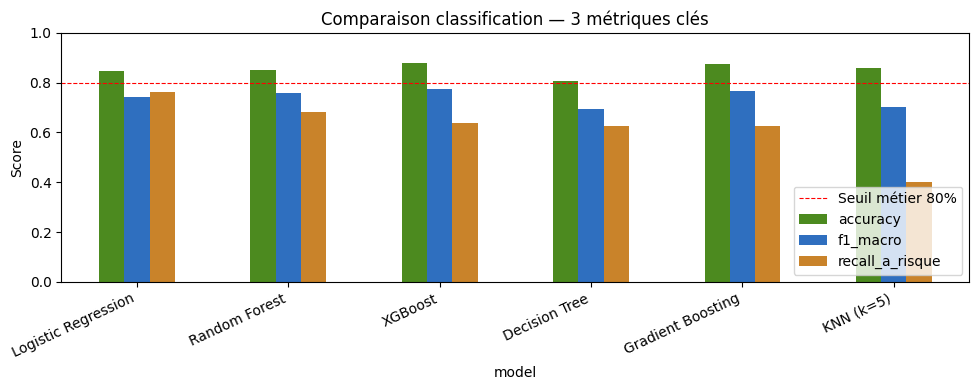

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
df_plot = df_clf.set_index("model")[["accuracy", "f1_macro", "recall_a_risque"]]
df_plot.plot(kind="bar", ax=ax, color=["#4c8a1f", "#2f6fbf", "#c9832a"])
ax.set_title("Comparaison classification — 3 métriques clés")
ax.set_ylabel("Score"); ax.set_ylim(0, 1)
ax.axhline(0.8, color="red", linestyle="--", linewidth=0.8, label="Seuil métier 80%")
ax.legend(loc="lower right")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


## 8. Comparaison des modèles de **régression** (RUL)

Métriques suivies :
- **MAE** : erreur moyenne en cycles — **métrique métier** (interprétable directement)
- **RMSE** : pénalise plus les grosses erreurs
- **R²** : variance expliquée (0 = aléatoire, 1 = parfait)

In [11]:
def eval_regressor(name, model, X_tr, y_tr, X_te, y_te):
    t0 = time.time()
    model.fit(X_tr, y_tr)
    fit_time = time.time() - t0
    y_pred = model.predict(X_te)
    return {
        "model": name,
        "MAE_cycles": round(mean_absolute_error(y_te, y_pred), 1),
        "RMSE_cycles": round(mean_squared_error(y_te, y_pred) ** 0.5, 1),
        "R2": round(r2_score(y_te, y_pred), 3),
        "fit_time_s": round(fit_time, 2),
    }

regressors = {
    "Linear Regression":   Pipeline([("sc", StandardScaler()), ("m", LinearRegression())]),
    "Decision Tree":       DecisionTreeRegressor(max_depth=12, random_state=42),
    "Random Forest":       RandomForestRegressor(n_estimators=200, max_depth=12,
                                                 random_state=42, n_jobs=-1),
    "Gradient Boosting":   GradientBoostingRegressor(n_estimators=200, max_depth=5, random_state=42),
    "XGBoost":             XGBRegressor(n_estimators=200, max_depth=6, learning_rate=0.1,
                                        random_state=42, n_jobs=-1),
}

reg_results = [eval_regressor(n, m, X_train, y_train_reg, X_test, y_test_reg)
               for n, m in regressors.items()]
df_reg = pd.DataFrame(reg_results).sort_values("MAE_cycles")
df_reg


,model,MAE_cycles,RMSE_cycles,R2,fit_time_s
2,Random Forest,18.9,24.1,0.839,8.59
4,XGBoost,19.1,24.9,0.829,0.48
3,Gradient Boosting,19.3,25.0,0.826,7.54
0,Linear Regression,20.9,26.0,0.812,0.01
1,Decision Tree,24.0,31.0,0.734,0.07


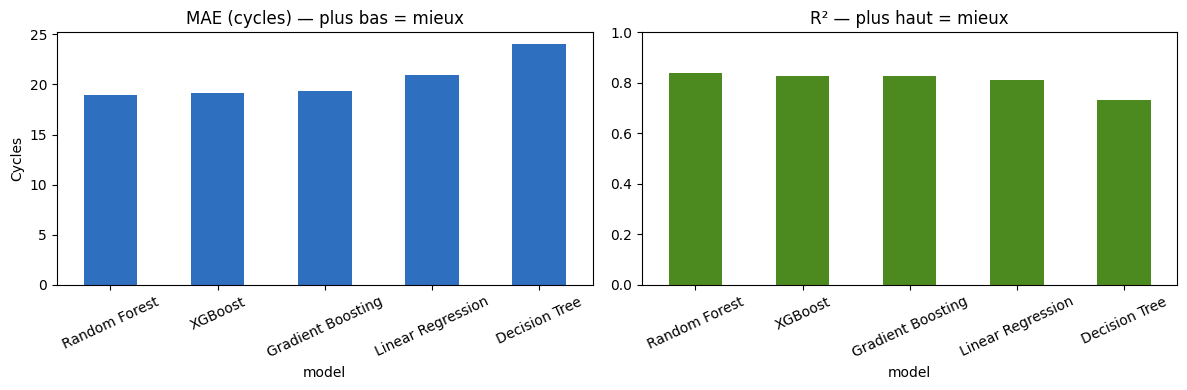

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df_reg.set_index("model")["MAE_cycles"].plot(kind="bar", ax=axes[0], color="#2f6fbf")
axes[0].set_title("MAE (cycles) — plus bas = mieux")
axes[0].set_ylabel("Cycles")
axes[0].tick_params(axis="x", rotation=25)

df_reg.set_index("model")["R2"].plot(kind="bar", ax=axes[1], color="#4c8a1f")
axes[1].set_title("R² — plus haut = mieux")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()


## 9. Validation croisée par groupe (`GroupKFold`)

Les sections 7 et 8 comparent les modèles sur **un seul découpage** train/test.
Un classement établi sur un seul tirage peut n'être qu'un artefact de ce tirage :
si les 10 machines tombées dans le jeu de test se dégradent d'une manière
inhabituelle, le modèle qui « gagne » est peut-être seulement celui qui s'accorde
le mieux avec ces 10 machines-là.

**Pourquoi `GroupKFold` et pas `KFold`** — exactement la même raison qu'en
section 6. Un `KFold` classique découperait ligne par ligne : les cycles 1 à 100
d'une machine serviraient à l'apprentissage pendant que ses cycles 101 à 200
serviraient au test. Le modèle aurait donc déjà vu la machine qu'on lui demande
d'évaluer, et le score serait optimiste. `GroupKFold(groups=machine_id)` garantit
qu'une machine entière est **soit** en apprentissage, **soit** en test.

**Ce qu'on regarde** :

| Indicateur | Ce qu'il dit |
|---|---|
| **Moyenne** sur les 5 folds | Estimation plus fiable que celle du split unique |
| **Écart-type** | Sensibilité du modèle au découpage — un modèle instable est risqué en production |
| **Étendue (min–max)** | Pire cas observé : c'est lui qui compte en maintenance prédictive |

Un modèle qui gagne de 0,02 avec un écart-type de 0,08 ne gagne pas réellement :
l'écart est noyé dans le bruit. C'est précisément ce que le split unique ne
permet pas de voir.

`GroupKFold` est **déterministe** (ni `shuffle` ni `random_state`) : les folds
sont identiques d'une exécution à l'autre, donc les résultats sont reproductibles.

Enfin, la validation croisée porte sur **l'ensemble des machines**, pas seulement
sur la partie « train » de la section 6 — c'est tout l'intérêt de la méthode :
chaque machine sert exactement une fois en test.

In [ ]:
N_SPLITS = 5
gkf = GroupKFold(n_splits=N_SPLITS)

# La validation croisée porte sur TOUTES les machines (pas seulement le train
# de la section 6) : chaque machine sert exactement une fois en test.
X_all      = df[FEATURES]
y_all_clf  = df["risk_level"].astype(str)
y_all_reg  = df["RUL"]
groups_all = df["machine_id"]

# Garde-fou explicite : aucune machine ne doit se retrouver des deux côtés d'un
# fold. C'est la propriété que GroupKFold garantit — on la vérifie plutôt que
# de la supposer.
for tr, te in gkf.split(X_all, y_all_clf, groups_all):
    partagees = set(groups_all.iloc[tr]) & set(groups_all.iloc[te])
    assert not partagees, f"Fuite de données : machines en train ET en test ({partagees})"

machines_par_fold = [len(set(groups_all.iloc[te])) for _, te in gkf.split(X_all, y_all_clf, groups_all)]
print(f"{N_SPLITS} folds — machines en test par fold : {machines_par_fold}")
print("Aucune machine partagée entre train et test.")

In [ ]:
def cv_classifier(name, model, X, y, groups, cv):
    """Validation croisée par groupe pour un classifieur.

    XGBoost est traité à part (il exige des labels numériques), exactement
    comme en section 7. L'encodeur est réajusté à chaque fold pour n'utiliser
    que les labels vus en apprentissage.
    """
    acc, f1m, rec = [], [], []
    for tr, te in cv.split(X, y, groups):
        X_tr, X_te = X.iloc[tr], X.iloc[te]
        y_tr, y_te = y.iloc[tr], y.iloc[te]
        m = clone(model)  # repart d'un modèle neuf à chaque fold
        if name == "XGBoost":
            le_fold = LabelEncoder().fit(y_tr)
            m.fit(X_tr, le_fold.transform(y_tr))
            y_pred = le_fold.inverse_transform(m.predict(X_te))
        else:
            m.fit(X_tr, y_tr)
            y_pred = m.predict(X_te)
        acc.append(accuracy_score(y_te, y_pred))
        f1m.append(f1_score(y_te, y_pred, average="macro"))
        rec.append(recall_score(y_te, y_pred, labels=["a_risque"], average="macro"))
    return {
        "model": name,
        "accuracy": round(np.mean(acc), 3),
        "f1_macro": round(np.mean(f1m), 3),
        "recall_a_risque": round(np.mean(rec), 3),
        "recall_ecart_type": round(np.std(rec), 3),
        "recall_min": round(np.min(rec), 3),
        "recall_max": round(np.max(rec), 3),
    }


# Réutilise le dictionnaire `classifiers` de la section 7 : une seule source de
# vérité pour les hyperparamètres.
df_cv_clf = pd.DataFrame(
    [cv_classifier(n, m, X_all, y_all_clf, groups_all, gkf) for n, m in classifiers.items()]
).sort_values("recall_a_risque", ascending=False)
df_cv_clf

In [ ]:
def cv_regressor(name, model, X, y, groups, cv):
    """Validation croisée par groupe pour un régresseur (RUL)."""
    mae, rmse, r2 = [], [], []
    for tr, te in cv.split(X, y, groups):
        X_tr, X_te = X.iloc[tr], X.iloc[te]
        y_tr, y_te = y.iloc[tr], y.iloc[te]
        m = clone(model).fit(X_tr, y_tr)
        y_pred = m.predict(X_te)
        mae.append(mean_absolute_error(y_te, y_pred))
        rmse.append(mean_squared_error(y_te, y_pred) ** 0.5)
        r2.append(r2_score(y_te, y_pred))
    return {
        "model": name,
        "MAE_cycles": round(np.mean(mae), 1),
        "MAE_ecart_type": round(np.std(mae), 1),
        "MAE_min": round(np.min(mae), 1),
        "MAE_max": round(np.max(mae), 1),
        "RMSE_cycles": round(np.mean(rmse), 1),
        "R2": round(np.mean(r2), 3),
    }


df_cv_reg = pd.DataFrame(
    [cv_regressor(n, m, X_all, y_all_reg, groups_all, gkf) for n, m in regressors.items()]
).sort_values("MAE_cycles")
df_cv_reg

In [ ]:
# --- Le classement du split unique tient-il en validation croisée ? ---
def comparer_classements(df_split, df_cv, metrique, ascendant):
    comp = (
        df_split[["model", metrique]].rename(columns={metrique: "split_unique"})
        .merge(df_cv[["model", metrique]].rename(columns={metrique: "cv_5_folds"}), on="model")
    )
    comp["rang_split"] = comp["split_unique"].rank(ascending=ascendant).astype(int)
    comp["rang_cv"] = comp["cv_5_folds"].rank(ascending=ascendant).astype(int)
    comp["ecart"] = (comp["cv_5_folds"] - comp["split_unique"]).round(3)
    comp["rang_change"] = np.where(comp["rang_split"] == comp["rang_cv"], "", "<-- change")
    return comp.sort_values("rang_cv")


print("=== CLASSIFICATION — stabilité du classement (recall a_risque) ===")
print(comparer_classements(df_clf, df_cv_clf, "recall_a_risque", ascendant=False).to_string(index=False))
print()
print("=== RÉGRESSION — stabilité du classement (MAE) ===")
print(comparer_classements(df_reg, df_cv_reg, "MAE_cycles", ascendant=True).to_string(index=False))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

d = df_cv_clf.set_index("model").sort_values("recall_a_risque")
axes[0].barh(d.index, d["recall_a_risque"], xerr=d["recall_ecart_type"],
             color="#2f6fbf", capsize=4)
axes[0].axvline(0.8, color="red", linestyle="--", linewidth=0.8, label="Seuil métier 80%")
axes[0].set_title("Recall a_risque — moyenne ± écart-type (5 folds)")
axes[0].set_xlim(0, 1)
axes[0].legend(loc="lower right")

d = df_cv_reg.set_index("model").sort_values("MAE_cycles", ascending=False)
axes[1].barh(d.index, d["MAE_cycles"], xerr=d["MAE_ecart_type"],
             color="#c9832a", capsize=4)
axes[1].set_title("MAE (cycles) — moyenne ± écart-type (5 folds)")
axes[1].set_xlabel("Cycles — plus bas = mieux")

plt.tight_layout()
plt.show()

In [ ]:
Path("outputs").mkdir(exist_ok=True)
df_cv_clf.to_csv("outputs/benchmark_cv_classification.csv", index=False)
df_cv_reg.to_csv("outputs/benchmark_cv_regression.csv", index=False)
print("Sauvegardé : outputs/benchmark_cv_classification.csv, outputs/benchmark_cv_regression.csv")


def to_markdown_table(df):
    """Rend une table markdown prête à coller dans docs/ (évite la dépendance
    à `tabulate`, absente de l'environnement CI)."""
    cols = list(df.columns)
    lignes = ["| " + " | ".join(cols) + " |",
              "|" + "|".join(["---"] * len(cols)) + "|"]
    for _, r in df.iterrows():
        lignes.append("| " + " | ".join(str(r[c]) for c in cols) + " |")
    return "\n".join(lignes)


print()
print("--- À coller dans docs/07_justification_modele.md ---")
print()
print(to_markdown_table(df_cv_clf))
print()
print(to_markdown_table(df_cv_reg))

## 10. Sélection des modèles finaux

**Règles de décision** :
- Classification : maximiser le **recall `a_risque`** moyen en validation croisée, arbitrer avec F1 macro à égalité
- Régression : minimiser la **MAE** moyenne en validation croisée
- À performance ~égale (écart inférieur à l'écart-type entre folds) : privilégier interprétabilité + rapidité (contraintes industrielles)

**La sélection s'appuie sur la validation croisée (section 9), pas sur le split
unique.** Un classement établi sur un seul découpage peut n'être qu'un artefact
de ce découpage ; faire une validation croisée puis sélectionner sur le split
unique reviendrait à ne pas s'en servir.

Le split unique reste utilisé ensuite, pour les analyses détaillées des sections
11 et 12 : elles ont besoin d'un jeu de test tenu à l'écart de l'apprentissage
pour produire une matrice de confusion et un nuage RUL réel/prédit lisibles.


In [13]:
# La sélection s'appuie sur la validation croisée (section 9). Les tables
# df_cv_* sont déjà triées par la métrique métier prioritaire de chaque tâche.
best_clf_name = df_cv_clf.iloc[0]["model"]
best_reg_name = df_cv_reg.iloc[0]["model"]

_c, _r = df_cv_clf.iloc[0], df_cv_reg.iloc[0]
print(f"Modèle classification retenu : {best_clf_name}")
print(f"  recall a_risque ({N_SPLITS} folds) : {_c['recall_a_risque']:.3f} "
      f"± {_c['recall_ecart_type']:.3f}  (pire fold : {_c['recall_min']:.3f})")
print(f"Modèle régression retenu     : {best_reg_name}")
print(f"  MAE ({N_SPLITS} folds) : {_r['MAE_cycles']:.1f} "
      f"± {_r['MAE_ecart_type']:.1f} cycles  (pire fold : {_r['MAE_max']:.1f})")

# Le split unique désignait-il les mêmes modèles ? Si non, c'est la validation
# croisée qui fait autorité — et l'écart mérite d'être commenté dans la doc.
if best_clf_name != df_clf.iloc[0]["model"]:
    print(f"\n[!] Split unique -> {df_clf.iloc[0]['model']} en classification, "
          f"CV -> {best_clf_name}. La CV fait autorité.")
if best_reg_name != df_reg.iloc[0]["model"]:
    print(f"[!] Split unique -> {df_reg.iloc[0]['model']} en régression, "
          f"CV -> {best_reg_name}. La CV fait autorité.")

# Les modèles ont tous été ajustés sur X_train en sections 7 et 8 (la validation
# croisée, elle, travaille sur des clones : elle ne perturbe pas cet état).
best_clf = classifiers[best_clf_name]
best_reg = regressors[best_reg_name]


Modèle classification retenu : Logistic Regression
Modèle régression retenu     : Random Forest


## 11. Analyse détaillée — classification retenue

In [14]:
if best_clf_name == "XGBoost":
    y_pred_clf = _LE.inverse_transform(best_clf.predict(X_test))
else:
    y_pred_clf = best_clf.predict(X_test)
print(classification_report(y_test_clf, y_pred_clf))


              precision    recall  f1-score   support

    a_risque       0.60      0.76      0.67       160
a_surveiller       0.58      0.68      0.62       350
      normal       0.97      0.90      0.93      1355

    accuracy                           0.85      1865
   macro avg       0.72      0.78      0.74      1865
weighted avg       0.87      0.85      0.85      1865



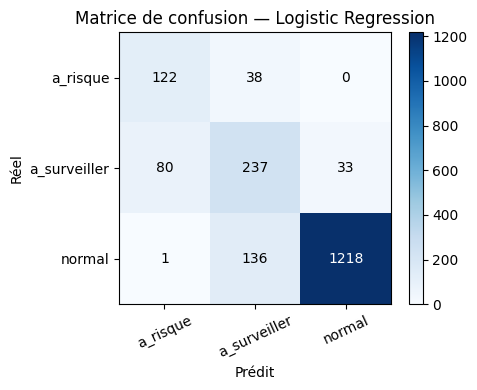

In [15]:
labels_order = ["a_risque", "a_surveiller", "normal"]
cm = confusion_matrix(y_test_clf, y_pred_clf, labels=labels_order)

fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(3)); ax.set_xticklabels(labels_order, rotation=25)
ax.set_yticks(range(3)); ax.set_yticklabels(labels_order)
ax.set_xlabel("Prédit"); ax.set_ylabel("Réel")
ax.set_title(f"Matrice de confusion — {best_clf_name}")
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max()/2 else "black")
plt.colorbar(im)
plt.tight_layout()
plt.show()


## 12. Analyse détaillée — régression retenue

MAE  : 18.9 cycles
RMSE : 24.1 cycles
R²   : 0.839


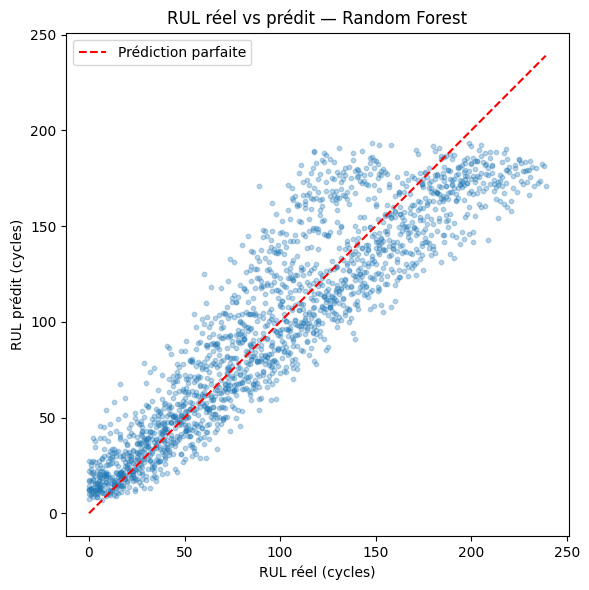

In [16]:
y_pred_reg = best_reg.predict(X_test)

print(f"MAE  : {mean_absolute_error(y_test_reg, y_pred_reg):.1f} cycles")
print(f"RMSE : {mean_squared_error(y_test_reg, y_pred_reg) ** 0.5:.1f} cycles")
print(f"R²   : {r2_score(y_test_reg, y_pred_reg):.3f}")

plt.figure(figsize=(6, 6))
plt.scatter(y_test_reg, y_pred_reg, alpha=0.3, s=10)
lim = max(y_test_reg.max(), y_pred_reg.max())
plt.plot([0, lim], [0, lim], "r--", label="Prédiction parfaite")
plt.xlabel("RUL réel (cycles)"); plt.ylabel("RUL prédit (cycles)")
plt.title(f"RUL réel vs prédit — {best_reg_name}")
plt.legend()
plt.tight_layout()
plt.show()


## 13. Pourquoi une machine est en maintenance ? Analyse d'importance des capteurs

Le RUL et le risk_level répondent à **"quand"**, pas **"pourquoi"**. Deux
analyses complémentaires pour répondre au "pourquoi" :

1. **Importance globale** : en moyenne sur tout le jeu de données, quels
   capteurs pèsent le plus dans les décisions du modèle ? Utile pour
   comprendre le modèle en général (documentation, audit).
2. **Score-Z par machine** : pour UNE machine précise, quel capteur est le
   plus éloigné de son comportement normal ? C'est ça qui sera exposé dans
   l'API — c'est l'information directement actionnable par un technicien
   ("regarde en premier la vibration axe X, elle est anormalement haute").

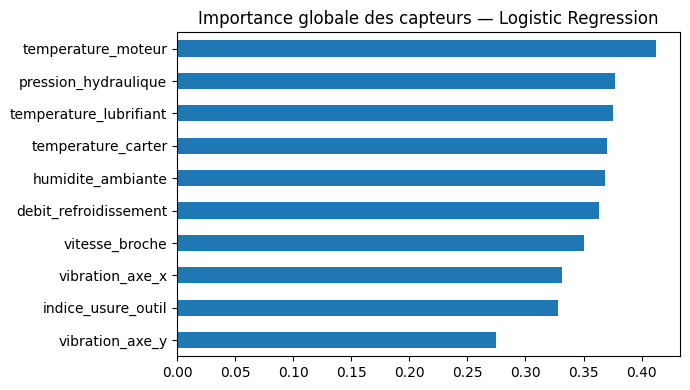

In [17]:
# --- 1. Importance globale ---
if hasattr(best_clf, "named_steps") and "m" in getattr(best_clf, "named_steps", {}):
    model_step = best_clf.named_steps["m"]
else:
    model_step = best_clf

if hasattr(model_step, "coef_"):
    # Modèle linéaire (Logistic Regression) : |coefficient| = importance
    # Multi-classe -> on moyenne la valeur absolue des coefficients sur les classes
    importances_clf = np.abs(model_step.coef_).mean(axis=0)
elif hasattr(model_step, "feature_importances_"):
    importances_clf = model_step.feature_importances_
else:
    importances_clf = np.zeros(len(FEATURES))

imp_clf_series = pd.Series(importances_clf, index=FEATURES).sort_values()
imp_clf_series.plot(kind="barh", figsize=(7, 4), title=f"Importance globale des capteurs — {best_clf_name}")
plt.tight_layout()
plt.show()


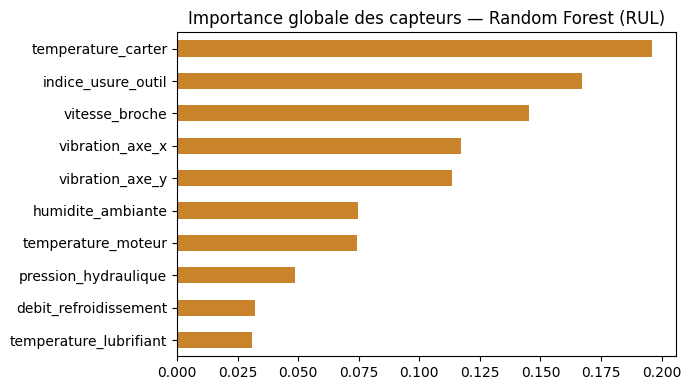

In [18]:
# Idem pour le modèle de régression (RUL)
if hasattr(best_reg, "named_steps") and "m" in getattr(best_reg, "named_steps", {}):
    reg_step = best_reg.named_steps["m"]
else:
    reg_step = best_reg

if hasattr(reg_step, "feature_importances_"):
    importances_reg = reg_step.feature_importances_
elif hasattr(reg_step, "coef_"):
    importances_reg = np.abs(reg_step.coef_)
else:
    importances_reg = np.zeros(len(FEATURES))

imp_reg_series = pd.Series(importances_reg, index=FEATURES).sort_values()
imp_reg_series.plot(kind="barh", figsize=(7, 4), color="#c9832a",
                     title=f"Importance globale des capteurs — {best_reg_name} (RUL)")
plt.tight_layout()
plt.show()


In [19]:
# --- 2. Statistiques de référence pour le score-Z par machine ---
# Calculées sur le TRAIN uniquement (jamais sur le test, pour éviter la fuite),
# et représentent le comportement "normal" moyen d'un capteur.
feature_stats = {
    f: {"mean": float(X_train[f].mean()), "std": float(X_train[f].std())}
    for f in FEATURES
}

print("Statistiques de référence (moyenne / écart-type) par capteur :")
pd.DataFrame(feature_stats).T.round(2)


Statistiques de référence (moyenne / écart-type) par capteur :


,mean,std
temperature_moteur,427.09,6.67
temperature_lubrifiant,437.01,6.57
temperature_carter,447.01,6.58
pression_hydraulique,477.01,6.57
vitesse_broche,496.99,6.55
vibration_axe_x,516.96,6.49
vibration_axe_y,527.05,6.59
debit_refroidissement,546.99,6.54
humidite_ambiante,557.04,6.54
indice_usure_outil,617.06,6.52


In [20]:
def capteur_principal(row, feature_stats):
    """Retourne le capteur dont la valeur est la plus anormale (score-Z le
    plus élevé en valeur absolue) pour une ligne de données donnée."""
    z_scores = {}
    for f, stats in feature_stats.items():
        std = stats["std"] if stats["std"] > 0 else 1e-6
        z_scores[f] = abs((row[f] - stats["mean"]) / std)
    return max(z_scores, key=z_scores.get)

# Exemple sur les 5 premières machines du jeu de test
exemples = df_test.head(5).copy()
exemples["capteur_principal"] = exemples.apply(lambda r: capteur_principal(r, feature_stats), axis=1)
exemples[["machine_id", "cycle_number"] + FEATURES[:3] + ["capteur_principal"]]


,machine_id,cycle_number,temperature_moteur,temperature_lubrifiant,temperature_carter,capteur_principal
2395,14,1,419.349894,430.913190,441.243389,vibration_axe_y
2396,14,2,419.240177,429.183216,439.837633,debit_refroidissement
2397,14,3,420.366170,430.861856,438.859449,debit_refroidissement
2398,14,4,421.167837,431.109217,439.712615,pression_hydraulique
2399,14,5,419.951927,432.753636,439.353270,humidite_ambiante


## 14. Export des prédictions (pour PostgreSQL)

Le `capteur_principal` est calculé pour chaque ligne et ajouté à l'export,
pour que l'API et les dashboards puissent l'exploiter directement.

In [21]:
Path("outputs").mkdir(exist_ok=True)

results = df_test[["machine_id", "cycle_number"]].copy()
results["rul_predit"] = y_pred_reg.round(0).astype(int)
results["risk_level_predit"] = y_pred_clf
results["risk_level_reel"] = y_test_clf.values
results["modele_classification"] = best_clf_name
results["modele_regression"] = best_reg_name
results["capteur_principal"] = df_test.apply(lambda r: capteur_principal(r, feature_stats), axis=1).values

results.to_csv("outputs/predictions.csv", index=False)
print("Sauvegardé : outputs/predictions.csv")
results.head(10)


Sauvegardé : outputs/predictions.csv


,machine_id,cycle_number,rul_predit,risk_level_predit,risk_level_reel,modele_classification,modele_regression,capteur_principal
2395,14,1,176,normal,normal,Logistic Regression,Random Forest,vibration_axe_y
2396,14,2,178,normal,normal,Logistic Regression,Random Forest,debit_refroidissement
2397,14,3,173,normal,normal,Logistic Regression,Random Forest,debit_refroidissement
2398,14,4,191,normal,normal,Logistic Regression,Random Forest,pression_hydraulique
2399,14,5,178,normal,normal,Logistic Regression,Random Forest,humidite_ambiante
2400,14,6,164,normal,normal,Logistic Regression,Random Forest,temperature_moteur
2401,14,7,184,normal,normal,Logistic Regression,Random Forest,indice_usure_outil
2402,14,8,175,normal,normal,Logistic Regression,Random Forest,debit_refroidissement
2403,14,9,185,normal,normal,Logistic Regression,Random Forest,temperature_lubrifiant
2404,14,10,179,normal,normal,Logistic Regression,Random Forest,temperature_moteur


## 15. Synthèse comparative

In [22]:
print("=== CLASSIFICATION ===")
print(df_clf.to_string(index=False))
print("\n=== REGRESSION ===")
print(df_reg.to_string(index=False))
print(f"\n>>> Retenus : {best_clf_name} (clf), {best_reg_name} (reg)")

# Export CSV du benchmark (livrable justification)
df_clf.to_csv("outputs/benchmark_classification.csv", index=False)
df_reg.to_csv("outputs/benchmark_regression.csv", index=False)


=== CLASSIFICATION ===
              model  accuracy  f1_macro  recall_a_risque  fit_time_s
Logistic Regression     0.846     0.743            0.762        0.03
      Random Forest     0.852     0.760            0.681        2.66
            XGBoost     0.879     0.776            0.637        0.87
      Decision Tree     0.808     0.693            0.625        0.07
  Gradient Boosting     0.876     0.768            0.625       23.51
          KNN (k=5)     0.857     0.701            0.400        0.02

=== REGRESSION ===
            model  MAE_cycles  RMSE_cycles    R2  fit_time_s
    Random Forest        18.9         24.1 0.839        8.59
          XGBoost        19.1         24.9 0.829        0.48
Gradient Boosting        19.3         25.0 0.826        7.54
Linear Regression        20.9         26.0 0.812        0.01
    Decision Tree        24.0         31.0 0.734        0.07

>>> Retenus : Logistic Regression (clf), Random Forest (reg)


## 16. Export des modèles entraînés

Sauvegarde des 2 modèles retenus + métadonnées (liste des features, mapping
des capteurs) afin que le pipeline d'inférence (`scripts/run_pipeline.py`)
puisse prédire sur de nouvelles données **sans ré-entraîner**.

In [23]:
import joblib
import json

Path("outputs/models").mkdir(parents=True, exist_ok=True)

joblib.dump(best_clf, "outputs/models/model_classification.joblib")
joblib.dump(best_reg, "outputs/models/model_regression.joblib")

# XGBoost prédit des labels numériques encodés : sauvegarder l'encodeur pour le décodage
uses_label_encoder = (best_clf_name == "XGBoost")
if uses_label_encoder:
    joblib.dump(_LE, "outputs/models/label_encoder.joblib")

metadata = {
    "features": FEATURES,
    "sensor_rename": SENSOR_RENAME,
    "model_classification": best_clf_name,
    "model_regression": best_reg_name,
    "classification_uses_label_encoder": uses_label_encoder,
    "risk_level_bins": [-1, 15, 50, None],  # None = np.inf
    "risk_level_labels": ["a_risque", "a_surveiller", "normal"],
    "sensor_alert_threshold": SEUIL_ALERTE_CAPTEUR,
    "feature_stats": feature_stats,  # moyenne/écart-type par capteur (train) — pour le score-Z du pipeline
    # Traçabilité de la validation : comment ces deux modèles ont été retenus.
    # Exigence d'auditabilité remontée par la Direction qualité (cf. 03_entretien_client.md).
    "validation": {
        "methode": "GroupKFold",
        "n_splits": int(N_SPLITS),
        "groupes": "machine_id",
        "recall_a_risque_cv": float(df_cv_clf.iloc[0]["recall_a_risque"]),
        "recall_a_risque_cv_ecart_type": float(df_cv_clf.iloc[0]["recall_ecart_type"]),
        "mae_cv_cycles": float(df_cv_reg.iloc[0]["MAE_cycles"]),
        "mae_cv_ecart_type": float(df_cv_reg.iloc[0]["MAE_ecart_type"]),
    },
}
with open("outputs/models/metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("Modèles exportés :")
print("  outputs/models/model_classification.joblib")
print("  outputs/models/model_regression.joblib")
if uses_label_encoder:
    print("  outputs/models/label_encoder.joblib")
print("  outputs/models/metadata.json")


Modèles exportés :
  outputs/models/model_classification.joblib
  outputs/models/model_regression.joblib
  outputs/models/metadata.json


## 17. Procédure d'entraînement — lot, mini-lot, online

Les sections précédentes entraînent **par lot** (*batch*) : on charge tout
l'historique en mémoire et on ajuste le modèle d'un coup. C'est le mode adapté
au volume actuel, mais ce n'est pas le seul, et le choix a des conséquences
opérationnelles directes pour MECHA (~10 000 points/min tous sites confondus,
cf. `03_entretien_client.md`).

| Mode | Principe | Quand c'est le bon choix |
|---|---|---|
| **Lot** (*batch*) | Tout l'historique, un seul ajustement | Le jeu tient en mémoire, réentraînement planifié |
| **Mini-lot** (*mini-batch*) | Paquets de N lignes, ajustements successifs | Le jeu ne tient plus en mémoire, réentraînement fréquent |
| **Online** | Une ligne à la fois, à mesure qu'elle arrive | Flux continu, adaptation immédiate, pas de stockage |

**Pourquoi c'est démontrable sur le modèle retenu** : la Logistic Regression a un
équivalent incrémental exact, `SGDClassifier(loss="log_loss")`. Même fonction de
coût, mais optimisée par descente de gradient stochastique — donc compatible avec
`partial_fit`. On compare bien trois façons d'entraîner *le même modèle*, pas
trois modèles différents.

Deux contraintes apparaissent dès qu'on quitte le mode batch :

1. **`class_weight="balanced"` est refusé par `partial_fit`** — en incrémental, le
   modèle ne connaît pas encore la distribution des classes. Il faut calculer les
   poids sur un échantillon représentatif de l'historique, puis les **figer**.
2. **Le `StandardScaler` doit être figé lui aussi** — on ne peut pas
   re-normaliser rétroactivement des données déjà apprises.

In [ ]:
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import precision_score
from sklearn.utils.class_weight import compute_class_weight

CLASSES = np.array(["a_risque", "a_surveiller", "normal"])
TAILLE_MINI_LOT, EPOQUES = 256, 5

# Contrainte 1 : poids de classes pré-calculés puis figés (partial_fit refuse
# class_weight="balanced" — le modèle ignore encore la distribution des classes).
POIDS_CLASSES = dict(zip(CLASSES, compute_class_weight("balanced", classes=CLASSES, y=y_train_clf.astype(str))))

# Contrainte 2 : scaler ajusté une fois sur l'historique puis figé — on ne peut
# pas re-normaliser rétroactivement des données déjà apprises.
scaler_inc = StandardScaler().fit(X_train)
Xtr_s, Xte_s = scaler_inc.transform(X_train), scaler_inc.transform(X_test)

y_tr_s, y_te_s = y_train_clf.astype(str), y_test_clf.astype(str)


def scores_mode(y_pred):
    """Recall ET précision : le recall seul est trompeur — un modèle qui prédit
    `a_risque` partout obtient un recall de 1,0 et ne sert à rien."""
    return {
        "recall_a_risque": round(recall_score(y_te_s, y_pred, labels=["a_risque"], average="macro"), 3),
        "precision_a_risque": round(precision_score(y_te_s, y_pred, labels=["a_risque"],
                                                    average="macro", zero_division=0), 3),
        "f1_macro": round(f1_score(y_te_s, y_pred, average="macro"), 3),
    }


def make_sgd(**kw):
    p = dict(loss="log_loss", class_weight=POIDS_CLASSES, random_state=42,
             learning_rate="constant", eta0=0.001)
    p.update(kw)
    return SGDClassifier(**p)


print("Poids de classes figés :", {k: round(v, 2) for k, v in POIDS_CLASSES.items()})

In [ ]:
resultats_modes = []

# --- 1. LOT : ce que font les sections 7 à 10 ---
t0 = time.time()
m_lot = Pipeline([("sc", StandardScaler()),
                  ("m", LogisticRegression(max_iter=1000, class_weight="balanced"))]).fit(X_train, y_tr_s)
resultats_modes.append({"mode": "Lot (batch)", "algo": "LogisticRegression", "passes": "convergence",
                        "lignes_par_maj": len(X_train), "temps_s": round(time.time() - t0, 2),
                        **scores_mode(m_lot.predict(X_test))})

# --- 2. MINI-LOT : partial_fit par paquets, plusieurs époques, données mélangées ---
# SGD suppose des échantillons i.i.d. : on mélange à chaque époque, sinon le
# modèle voit une machine entière d'affilée (que des cycles "normal", puis que
# des "a_risque") et oscille.
t0 = time.time()
m_mini = make_sgd()
rng_mini = np.random.default_rng(42)
histo_epoques = []
for ep in range(EPOQUES):
    idx = rng_mini.permutation(len(Xtr_s))
    for debut in range(0, len(idx), TAILLE_MINI_LOT):
        lot = idx[debut:debut + TAILLE_MINI_LOT]
        m_mini.partial_fit(Xtr_s[lot], y_tr_s.iloc[lot], classes=CLASSES)
    histo_epoques.append({"epoque": ep + 1, **scores_mode(m_mini.predict(Xte_s))})
resultats_modes.append({"mode": f"Mini-lot ({TAILLE_MINI_LOT})", "algo": "SGDClassifier",
                        "passes": f"{EPOQUES} époques", "lignes_par_maj": TAILLE_MINI_LOT,
                        "temps_s": round(time.time() - t0, 2), **scores_mode(m_mini.predict(Xte_s))})

# --- 3. ONLINE : une ligne à la fois, une seule passe (on ne revoit jamais
#        une donnée déjà consommée — c'est la définition de l'online) ---
t0 = time.time()
m_online = make_sgd()
for i in np.random.default_rng(42).permutation(len(Xtr_s)):
    m_online.partial_fit(Xtr_s[i:i + 1], y_tr_s.iloc[i:i + 1], classes=CLASSES)
resultats_modes.append({"mode": "Online", "algo": "SGDClassifier", "passes": "1 passe",
                        "lignes_par_maj": 1, "temps_s": round(time.time() - t0, 2),
                        **scores_mode(m_online.predict(Xte_s))})

# --- 3bis. ONLINE dans l'ordre réel d'arrivée (machine par machine, cycle par
#           cycle) : c'est ce qui se passerait vraiment sur le flux capteurs ---
t0 = time.time()
m_online_nat = make_sgd()
for i in range(len(Xtr_s)):
    m_online_nat.partial_fit(Xtr_s[i:i + 1], y_tr_s.iloc[i:i + 1], classes=CLASSES)
resultats_modes.append({"mode": "Online (ordre d'arrivée)", "algo": "SGDClassifier", "passes": "1 passe",
                        "lignes_par_maj": 1, "temps_s": round(time.time() - t0, 2),
                        **scores_mode(m_online_nat.predict(Xte_s))})

df_modes = pd.DataFrame(resultats_modes)
df_modes

In [ ]:
# --- Le piège du recall : vérifier ce que chaque mode prédit réellement ---
# Un modèle qui crie "a_risque" trop souvent gonfle son recall et devient
# inutilisable en atelier (les équipes cessent de croire les alertes).
repartition = {}
for nom, m, X in [("Lot", m_lot, X_test), ("Mini-lot", m_mini, Xte_s),
                  ("Online", m_online, Xte_s), ("Online (arrivée)", m_online_nat, Xte_s)]:
    repartition[nom] = pd.Series(m.predict(X)).value_counts(normalize=True).round(3)
repartition["Réel"] = y_te_s.value_counts(normalize=True).round(3)

print("Répartition des classes prédites (vs réalité) :")
print(pd.DataFrame(repartition).fillna(0).to_string())
print()
print("Stabilité du mini-lot d'une époque à l'autre :")
print(pd.DataFrame(histo_epoques).to_string(index=False))

In [ ]:
# --- Le taux d'apprentissage est LE paramètre décisif en incrémental ---
# En batch, sklearn gère la convergence. En incrémental, c'est à nous : un eta0
# trop faible n'apprend rien, trop fort fait osciller le modèle.
resultats_lr = []
for nom, kw in [("optimal (défaut sklearn)", dict(learning_rate="optimal")),
                ("constant eta0=0.01", dict(learning_rate="constant", eta0=0.01)),
                ("constant eta0=0.001", dict(learning_rate="constant", eta0=0.001)),
                ("constant eta0=0.0001", dict(learning_rate="constant", eta0=0.0001)),
                ("adaptive eta0=0.01", dict(learning_rate="adaptive", eta0=0.01))]:
    m = make_sgd(**kw)
    r = np.random.default_rng(42)
    for _ in range(EPOQUES):
        idx = r.permutation(len(Xtr_s))
        for debut in range(0, len(idx), TAILLE_MINI_LOT):
            lot = idx[debut:debut + TAILLE_MINI_LOT]
            m.partial_fit(Xtr_s[lot], y_tr_s.iloc[lot], classes=CLASSES)
    resultats_lr.append({"taux_apprentissage": nom, **scores_mode(m.predict(Xte_s))})

df_lr = pd.DataFrame(resultats_lr)
df_lr

In [ ]:
Path("outputs").mkdir(exist_ok=True)
df_modes.to_csv("outputs/benchmark_modes_entrainement.csv", index=False)
df_lr.to_csv("outputs/benchmark_taux_apprentissage.csv", index=False)

meilleur = df_modes.sort_values("f1_macro", ascending=False).iloc[0]
print(f"Mode retenu pour MECHA : {meilleur['mode']} "
      f"(F1 {meilleur['f1_macro']}, recall {meilleur['recall_a_risque']}, "
      f"{meilleur['temps_s']} s)")
print()
print("Exporté : outputs/benchmark_modes_entrainement.csv, outputs/benchmark_taux_apprentissage.csv")
print("Synthèse argumentée : docs/08_procedure_entrainement.md")